In [1]:
# imports et réglages figés
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
average_precision_score, roc_auc_score, brier_score_loss,
confusion_matrix, recall_score, PrecisionRecallDisplay,
)
from sklearn.model_selection import cross_val_score
from inclusion_financiere.config import RANDOM_STATE, ROOT
from inclusion_financiere.data import get_train_test
from inclusion_financiere.evaluate import cv, expected_calibration_error, cout_total, bootstrap_ci
from inclusion_financiere.pipeline import pipe

X_train, X_test, y_train, y_test = get_train_test()

params_retenus = json.loads((ROOT / 'reports' /'best_params.json').read_text())
seuil_retenu = json.loads((ROOT / 'reports' / 'decision.json').read_text())['seuil_retenu']

meilleur_modele = pipe(LGBMClassifier(**params_retenus, random_state=RANDOM_STATE, verbose=-1))


In [2]:
final = CalibratedClassifierCV(meilleur_modele, method='isotonic', cv=5)
final.fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
y_pred = (p_test >= seuil_retenu).astype(int)


In [3]:
#le tableau final
yt = y_test.to_numpy()
ic = bootstrap_ci(yt, p_test, average_precision_score)
final_table = pd.Series({
    'PR-AUC': round(average_precision_score(yt, p_test), 4),
    'PR-AUC IC 95 %': f'[{ic[0]:.4f} ; {ic[1]:.4f}]',
    'ROC-AUC': round(roc_auc_score(yt, p_test), 4),
    'Brier': round(brier_score_loss(yt, p_test), 4),
    'ECE': round(expected_calibration_error(yt, p_test), 4),
    'Seuil retenu': round(seuil_retenu, 4),
    'Coût total (USD)': cout_total(yt, y_pred),
    'Matrice [[TN, FP], [FN, TP]]': confusion_matrix(yt, y_pred, labels=[0,1]).tolist(),
})
final_table

PR-AUC                                             0.5941
PR-AUC IC 95 %                          [0.5561 ; 0.6316]
ROC-AUC                                            0.8758
Brier                                              0.0823
ECE                                                0.0122
Seuil retenu                                       0.0909
Coût total (USD)                                   1040.5
Matrice [[TN, FP], [FN, TP]]    [[2812, 1231], [85, 577]]
dtype: object

In [4]:
#Q10.2 : comparer avec la validation croisée

cv_pr = cross_val_score(final, X_train, y_train, cv=cv, scoring='average_precision')
print(f'CV : {cv_pr.mean():.4f} ± {cv_pr.std():.4f}')
print(f'Test : {average_precision_score(yt, p_test):.4f}, IC 95 % [{ic[0]:.4f} ; {ic[1]:.4f}]')
print('La CV tombe dans l’IC du test :', ic[0] <= cv_pr.mean() <= ic[1])

CV : 0.5779 ± 0.0233
Test : 0.5941, IC 95 % [0.5561 ; 0.6316]
La CV tombe dans l’IC du test : True


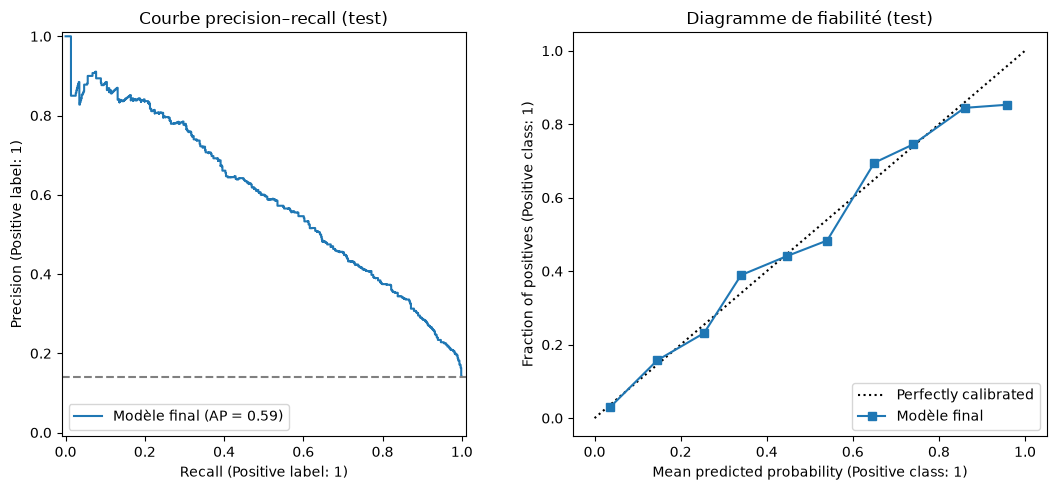

In [5]:
# figures pour le README
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
PrecisionRecallDisplay.from_predictions(yt, p_test, ax=axes[0], name='Modèle final')
axes[0].axhline(yt.mean(), ls='--', color='gray') # hasard = prévalence
axes[0].set_title('Courbe precision–recall (test)')
CalibrationDisplay.from_predictions(yt, p_test, n_bins=10, ax=axes[1], name='Modèle final')
axes[1].set_title('Diagramme de fiabilité (test)')
plt.tight_layout()
plt.savefig(ROOT / 'reports' / 'figures' / 'test_pr_fiabilite.png', dpi=150)
plt.show()


In [7]:
#importance par permutation (11.1)
from sklearn.inspection import permutation_importance
modele_entraine = pipe(LGBMClassifier(**params_retenus, 
    random_state=RANDOM_STATE, verbose=-1))
modele_entraine.fit(X_train, y_train)
pi = permutation_importance(
modele_entraine, X_test, y_test, scoring='average_precision',
    n_repeats=10, random_state=RANDOM_STATE,
)
imp_perm = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp_perm


education_level           0.212922
job_type                  0.110872
country                   0.067052
cellphone_access          0.047012
age_of_respondent         0.040028
location_type             0.026103
gender_of_respondent      0.008112
relationship_with_head    0.003769
marital_status            0.001456
household_size           -0.002045
dtype: float64

c:\Users\hp\Desktop\DATA SCIENTISTE AVEC FORCE N\AIMS_Programme\PROJET A RENDRE\AIMS-Module5_DS_ML_Oct-Nov-2026\inclusion-financiere\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


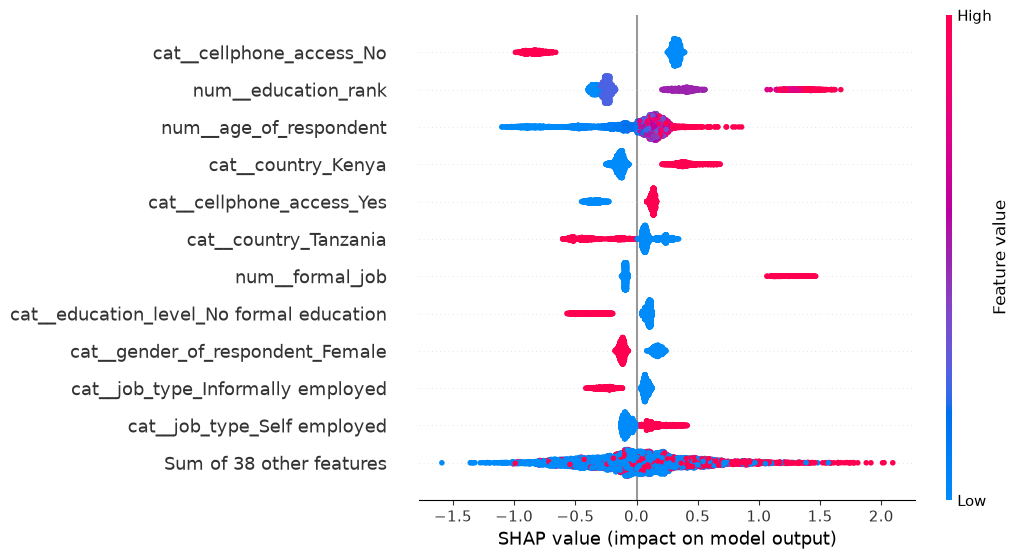

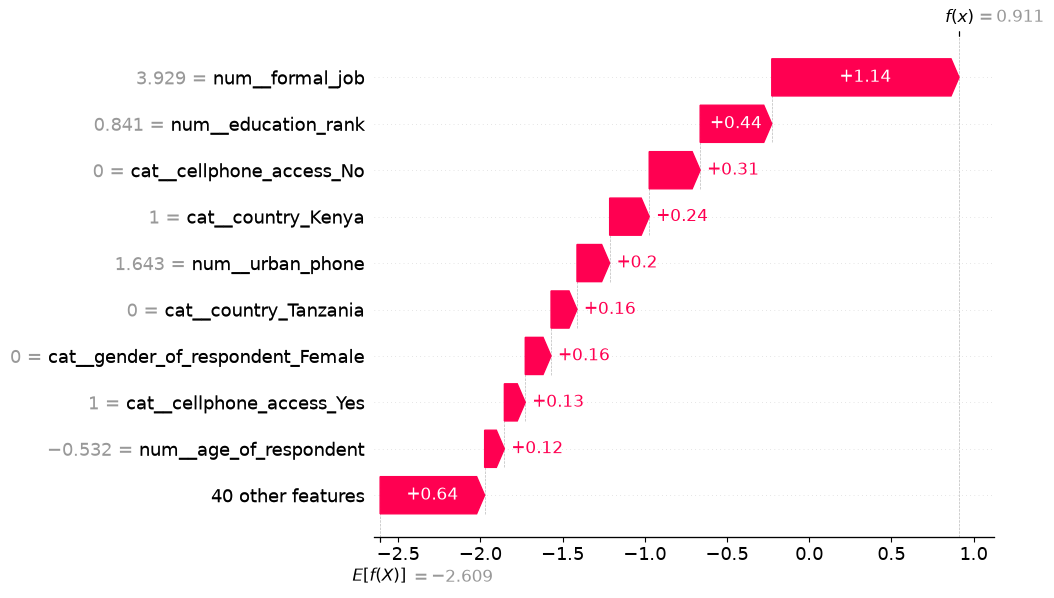

True

In [ ]:
#SHAP (11.2)

import shap
prep, lgbm = modele_entraine[:-1], modele_entraine[-1]
X_t = prep.transform(X_test)
noms = prep[-1].get_feature_names_out() # noms après le ColumnTransformer
X_t = pd.DataFrame(X_t.toarray() if hasattr(X_t, 'toarray') else X_t, columns=noms)
sv = shap.TreeExplainer(lgbm)(X_t)
shap.plots.beeswarm(sv, max_display=12, show=False) # vue globale
plt.savefig(ROOT / 'reports' / 'figures' / 'shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
shap.plots.waterfall(sv[0], max_display=10) # une personne

# Vérification : valeur de base + somme des contributions = log-odds du modèle

np.allclose(sv.base_values[:5] + sv.values[:5].sum(1),
lgbm.predict(X_t.iloc[:5], raw_score=True))

In [ ]:
# Agréger SHAP par variable d'origine
# On additionne d'abord les valeurs SHAP AVEC leur signe pour chaque variable
# (les colonnes one-hot d'une même variable portent la même information),
# puis on prend la valeur absolue et la moyenne sur les personnes.

from inclusion_financiere.pipeline import CAT_FE, NUM_FE

def variable_origine(nom):
    nom = nom.split('__', 1)[1]  # retire le préfixe cat__ ou num__
    candidats = [c for c in CAT_FE + NUM_FE if nom == c or nom.startswith(c + '_')]
    return max(candidats, key=len)

shap_signe = pd.DataFrame(sv.values, columns=noms)
shap_par_variable = (
    shap_signe.T.groupby(variable_origine).sum().T
    .abs().mean().sort_values(ascending=False)
)
shap_par_variable

In [12]:
shap_signe = pd.DataFrame(sv.values, columns=noms)
shap_par_variable = (shap_signe.T.groupby(variable_origine).sum().T
                     .abs().mean().sort_values(ascending=False))
shap_par_variable

cellphone_access          0.641791
country                   0.391816
education_rank            0.383909
job_type                  0.226256
gender_of_respondent      0.213051
age_of_respondent         0.210649
education_level           0.167102
formal_job                0.161373
urban_phone               0.097272
age_squared               0.084133
location_type             0.074162
relationship_with_head    0.043799
is_head                   0.040897
age_group                 0.038394
marital_status            0.035788
household_size            0.030275
dtype: float64

In [13]:
## Q9.1 : fiabilité du modèle après correction
for genre in ['Female', 'Male']:
    masque = (X_test['gender_of_respondent'] == genre).to_numpy()
    print(genre, 'recall =', round(recall_score(yt[masque], y_pred[masque]), 3),
          '| part contactée =', round(y_pred[masque].mean(), 3))


Female recall = 0.839 | part contactée = 0.291
Male recall = 0.899 | part contactée = 0.52


In [14]:
from sklearn.metrics import recall_score, precision_score
rng = np.random.default_rng(RANDOM_STATE)

def metriques(m):
    return dict(n=int(m.sum()),
                prevalence=yt[m].mean(),
                recall=recall_score(yt[m], y_pred[m]),
                precision=precision_score(yt[m], y_pred[m], zero_division=0),
                contactee=y_pred[m].mean())

mF = (X_test['gender_of_respondent'] == 'Female').to_numpy()
mM = ~mF
print(pd.DataFrame({'Female': metriques(mF), 'Male': metriques(mM)}).round(3))

# IC bootstrap de l'écart de rappel (Male - Female)
iF, iM = np.where(mF)[0], np.where(mM)[0]
ecarts = []
for _ in range(1000):
    bF, bM = rng.choice(iF, len(iF)), rng.choice(iM, len(iM))
    ecarts.append(recall_score(yt[bM], y_pred[bM]) - recall_score(yt[bF], y_pred[bF]))
print(np.percentile(ecarts, [2.5, 97.5]).round(3))

              Female      Male
n           2792.000  1913.000
prevalence     0.109     0.187
recall         0.839     0.899
precision      0.314     0.324
contactee      0.291     0.520
[0.013 0.111]
